In [1]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import skimage
import torch
import torch.nn as nn
import torch.nn.functional as F
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight

device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)


Device: cuda


In [2]:
!mkdir -p /content/oxford-iiit-pet
!tar -xzf /content/images.tar.gz -C /content/oxford-iiit-pet
!tar -xzf /content/annotations.tar.gz -C /content/oxford-iiit-pet

In [3]:
# Change only this path to the folder that contains BOTH "images" and "annotations".
# Example for local Jupyter on Windows:
# DATASET_ROOT = r"C:\Users\YourName\Downloads\oxford-iiit-pet"
# Example if the notebook is placed beside the two extracted folders (including Colab /content):
DATASET_ROOT = "/content/oxford-iiit-pet"

data_dir = os.path.join(DATASET_ROOT, "images")
annotation_dir = os.path.join(DATASET_ROOT, "annotations")
mask_dir = os.path.join(annotation_dir, "trimaps")
trainval_file = os.path.join(annotation_dir, "trainval.txt")
test_file = os.path.join(annotation_dir, "test.txt")

print('Dataset root:', DATASET_ROOT)
print('Images:', data_dir)
print('Masks :', mask_dir)
print('trainval.txt:', trainval_file)
print('test.txt    :', test_file)


Dataset root: /content/oxford-iiit-pet
Images: /content/oxford-iiit-pet/images
Masks : /content/oxford-iiit-pet/annotations/trimaps
trainval.txt: /content/oxford-iiit-pet/annotations/trainval.txt
test.txt    : /content/oxford-iiit-pet/annotations/test.txt


In [4]:
def read_annotation_file(file_path):
    info = pd.read_csv(
        file_path,
        sep=r'\s+',
        comment='#',
        header=None,
        names=['image_id', 'class_id', 'species', 'breed_id']
    )

    info['class_id'] = info['class_id'] - 1
    return info


trainval_info = read_annotation_file(trainval_file)
test_info = read_annotation_file(test_file)

NUM_CLASSES = len(set(trainval_info['class_id']).union(set(test_info['class_id'])))
class_names = [''] * NUM_CLASSES
class_species = [''] * NUM_CLASSES

for table in [trainval_info, test_info]:
    for i in range(len(table)):
        image_id = str(table.iloc[i]['image_id'])
        class_id = int(table.iloc[i]['class_id'])
        species_id = int(table.iloc[i]['species'])

        parts = image_id.split('_')
        breed_name = ' '.join(parts[:-1]).title()

        class_names[class_id] = breed_name
        class_species[class_id] = 'Cat' if species_id == 1 else 'Dog'

print('Training/validation source samples:', len(trainval_info))
print('Official test samples:', len(test_info))
print('Number of breed classes:', NUM_CLASSES)
print('First five breed names:', class_names[:5])


Training/validation source samples: 3680
Official test samples: 3669
Number of breed classes: 37
First five breed names: ['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle']


## 3. Mask conversion required by the guideline
The project requires a **binary mask**:

- Pet foreground = `1`
- Background = `0`
- Boundary/unclassified pixels are merged into foreground.

### Important audit correction
Oxford trimap PNG files may be **palette PNGs**. With a palette PNG, `plt.imread` can return an RGB/RGBA color image instead of the raw integer class IDs. Therefore it is unsafe to simply take the first channel and assume it contains labels `1,2,3`.

The function below handles both cases:
- a 2-D label image (raw/normalized labels), or
- an RGB/RGBA palette-decoded image.

For the Oxford palette, the background class is the **green-dominant** palette entry; the foreground and boundary entries are not green-dominant. Since the project merges foreground + boundary, the binary mask is simply `not background`.

No new image-reading package is introduced; this still uses `plt.imread`, NumPy logic, and `skimage.transform.resize`, all consistent with the labs.


In [5]:
def ret_binary_trimap(mask):
    # Case 1: plt.imread returned a 2-D label image.
    if mask.ndim == 2:
        # PNG integer labels may be scaled to [0,1] by plt.imread.
        if mask.max() <= 1:
            # Background label is 2, so in normalized PNG form it is approximately 2/255.
            background = (mask > 1.5/255.0) & (mask < 2.5/255.0)
        else:
            background = (mask == 2)

    # Case 2: palette PNG was decoded to RGB/RGBA.
    else:
        rgb = mask[:, :, :3]
        # Oxford/PASCAL-style palette: class 2 (background) is green-dominant.
        background = (rgb[:, :, 1] > rgb[:, :, 0]) & (rgb[:, :, 1] > rgb[:, :, 2])

    # Required binary problem: foreground + boundary = 1, background = 0.
    binary = (~background).astype(np.float32)
    return binary


def get_data(row, data_dir, mask_dir, reshape=True, image_size=(128, 128)):
    image_name = str(row['image_id']) + '.jpg'
    mask_name = str(row['image_id']) + '.png'

    im = plt.imread(os.path.join(data_dir, image_name))
    mask = plt.imread(os.path.join(mask_dir, mask_name))
    mask = ret_binary_trimap(mask)

    if reshape:
        im = skimage.transform.resize(im, image_size, anti_aliasing=True)

        # Keep only the first 3 channels (RGB)
        if im.shape[-1] == 4:
            im = im[:, :, :3]

        mask = skimage.transform.resize(mask, image_size, anti_aliasing=False)
        mask = (mask >= 0.5).astype(np.float32)

    im = im.astype(np.float32)
    mask = mask.astype(np.float32)

    return im, mask, int(row['class_id'])


## 4. Verify the mask conversion before training
This is an important sanity check. It prints the raw mask shape and the unique binary values after conversion. The binary mask should contain `0` and `1` (for a normal image containing both pet and background).

The next 3×3 overlay cell is the strongest visual confirmation that the foreground/background interpretation is correct.


In [6]:
check_row = trainval_info.iloc[0]
raw_mask = plt.imread(os.path.join(mask_dir, str(check_row['image_id']) + '.png'))
binary_check = ret_binary_trimap(raw_mask)

print('Raw mask shape:', raw_mask.shape)
print('Raw mask minimum:', raw_mask.min(), '| maximum:', raw_mask.max())
print('Binary mask unique values:', np.unique(binary_check))


Raw mask shape: (500, 394)
Raw mask minimum: 0.003921569 | maximum: 0.011764706
Binary mask unique values: [0. 1.]


## 5. Required 9 random image + mask overlays (3×3)
This directly satisfies the required dataset-exploration visualization.

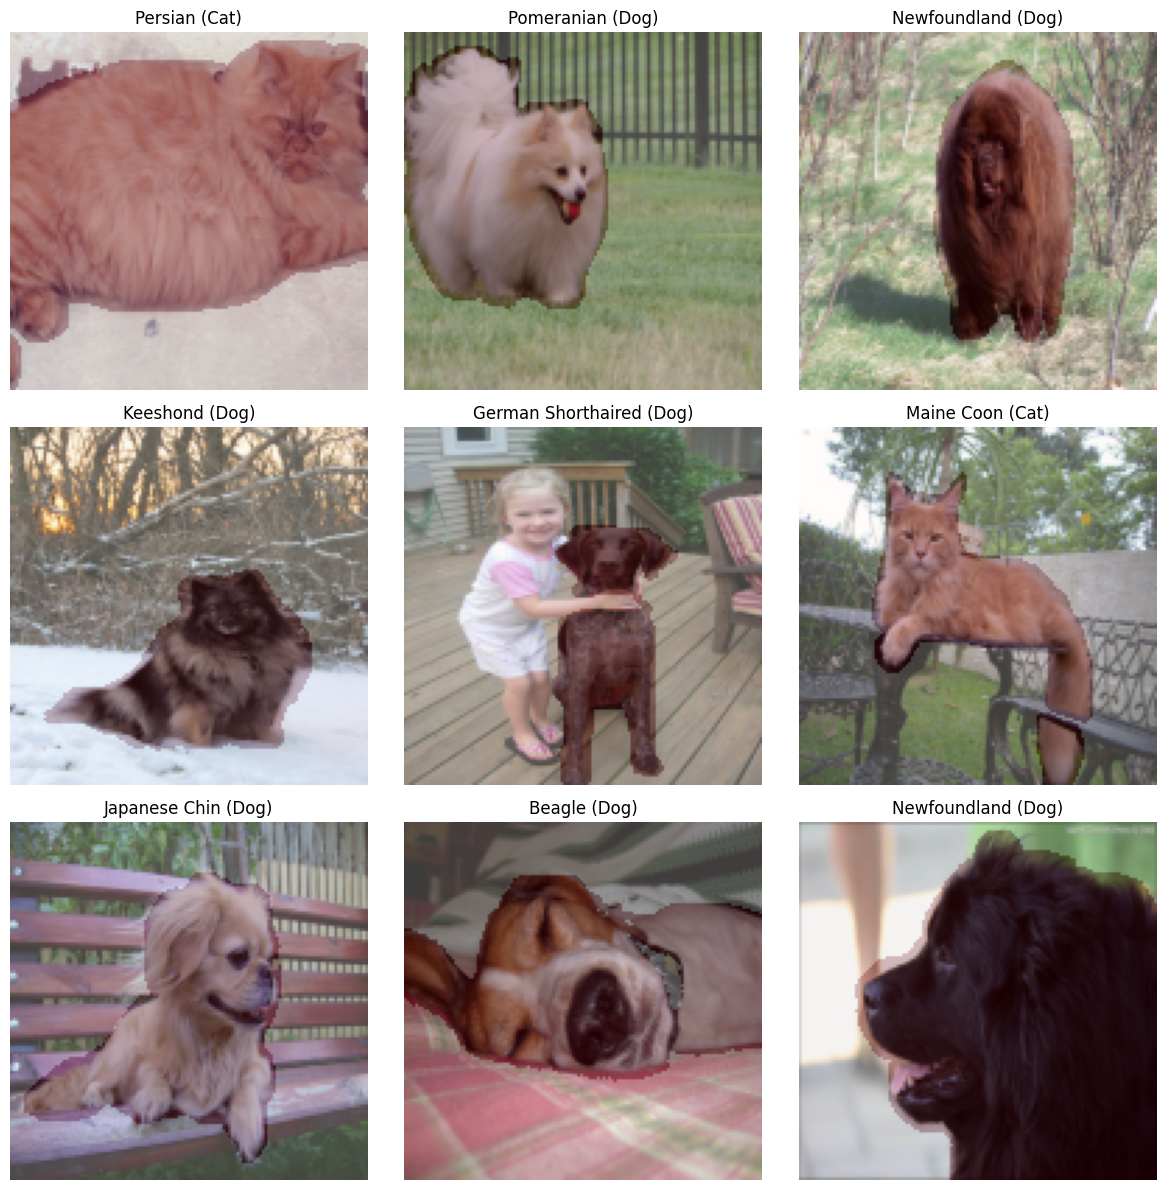

In [7]:
def show_9_random_overlays(info, data_dir, mask_dir, alpha=0.25):
    random_indices = np.random.choice(len(info), size=9, replace=False)

    plt.figure(figsize=(12, 12))
    for plot_i, data_i in enumerate(random_indices):
        row = info.iloc[data_i]
        im, mask, label = get_data(row, data_dir, mask_dir, reshape=True, image_size=(128, 128))

        plt.subplot(3, 3, plot_i + 1)
        plt.imshow(im)
        plt.imshow(mask, cmap='Reds', alpha=alpha)
        plt.axis('off')
        plt.title(class_names[label] + ' (' + class_species[label] + ')')

    plt.tight_layout()
    plt.show()

show_9_random_overlays(trainval_info, data_dir, mask_dir)


## 6. Dataset class distribution
A simple manual count is used so the exploration stays lightweight and does not require any extra metric/statistics package.


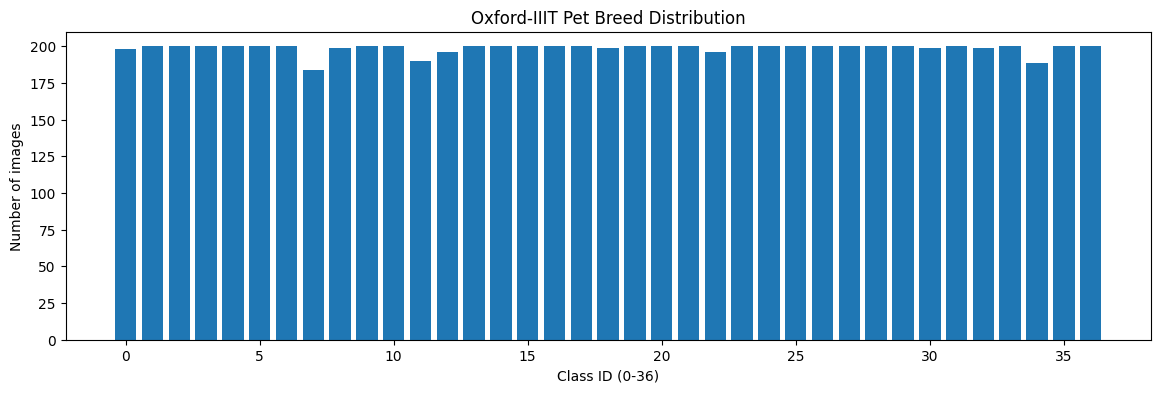

Minimum samples in a breed: 184.0
Maximum samples in a breed: 200.0


In [8]:
class_counts = np.zeros(NUM_CLASSES)

for table in [trainval_info, test_info]:
    for i in range(len(table)):
        class_id = int(table.iloc[i]['class_id'])
        class_counts[class_id] += 1

plt.figure(figsize=(14, 4))
plt.bar(np.arange(NUM_CLASSES), class_counts)
plt.xlabel(f'Class ID (0-{NUM_CLASSES-1})')
plt.ylabel('Number of images')
plt.title('Oxford-IIIT Pet Breed Distribution')
plt.show()

print('Minimum samples in a breed:', class_counts.min())
print('Maximum samples in a breed:', class_counts.max())


## 7. Train / validation / test split
The dataset already provides `trainval.txt` and `test.txt`. We preserve the official **test** set and split `trainval` into **training** and **validation** using `train_test_split(..., stratify=...)`, matching the splitting method used in the labs.

In [9]:
train_idx, val_idx = train_test_split(
    np.arange(len(trainval_info)),
    test_size=0.20,
    stratify=trainval_info['class_id'].values,
    random_state=125
)

train_info = trainval_info.iloc[train_idx]
val_info = trainval_info.iloc[val_idx]

print('Training samples  :', len(train_info))
print('Validation samples:', len(val_info))
print('Test samples      :', len(test_info))
print('Total             :', len(train_info) + len(val_info) + len(test_info))


Training samples  : 2944
Validation samples: 736
Test samples      : 3669
Total             : 7349


## 8. Read and resize all three sets
This follows Lab 8's `read_data` approach. Images are stored as `[C,H,W]` because the project uses RGB input, while masks remain `[H,W]`.

In [10]:
IMAGE_SIZE = (128, 128)


def read_data(info, data_dir, mask_dir, image_size=IMAGE_SIZE):
    x = []
    y_mask = []
    y_label = []

    for i in range(len(info)):
        row = info.iloc[i]
        im, mask, label = get_data(row, data_dir, mask_dir, reshape=True, image_size=image_size)

        # RGB arrays are H x W x C. PyTorch Conv2d expects C x H x W.
        im = np.transpose(im, (2, 0, 1))


        x.append(im)
        y_mask.append(mask)
        y_label.append(label)

        if (i + 1) % 500 == 0:
            print('Read', i + 1, '/', len(info), 'samples')


    return (
        np.array(x, dtype=np.float32),
        np.array(y_mask, dtype=np.float32),
        np.array(y_label, dtype=np.int64)
    )


x_train, y_mask_train, y_train = read_data(train_info, data_dir, mask_dir)
x_val, y_mask_val, y_val = read_data(val_info, data_dir, mask_dir)
x_test, y_mask_test, y_test = read_data(test_info, data_dir, mask_dir)

print('x_train:', x_train.shape, '| y_mask_train:', y_mask_train.shape, '| y_train:', y_train.shape)
print('x_val  :', x_val.shape, '| y_mask_val  :', y_mask_val.shape, '| y_val  :', y_val.shape)
print('x_test :', x_test.shape, '| y_mask_test :', y_mask_test.shape, '| y_test :', y_test.shape)


Read 500 / 2944 samples
Read 1000 / 2944 samples
Read 1500 / 2944 samples
Read 2000 / 2944 samples
Read 2500 / 2944 samples
Read 500 / 736 samples
Read 500 / 3669 samples
Read 1000 / 3669 samples
Read 1500 / 3669 samples
Read 2000 / 3669 samples
Read 2500 / 3669 samples
Read 3000 / 3669 samples
Read 3500 / 3669 samples
x_train: (2944, 3, 128, 128) | y_mask_train: (2944, 128, 128) | y_train: (2944,)
x_val  : (736, 3, 128, 128) | y_mask_val  : (736, 128, 128) | y_val  : (736,)
x_test : (3669, 3, 128, 128) | y_mask_test : (3669, 128, 128) | y_test : (3669,)


## 9. Normalize using only training statistics
For RGB photographs, normalization is done **per colour channel** using the training set only. This keeps normal colour/texture information for breed classification while still standardizing the input. Validation and test use the training mean and standard deviation.

In [11]:
# Per-channel normalization for RGB images.
# x shape is [N, C, H, W], so we average over N, H and W and keep C.
train_mean = x_train.mean(axis=(0, 2, 3), keepdims=True)
train_std = x_train.std(axis=(0, 2, 3), keepdims=True)

x_train = (x_train - train_mean) / (train_std + 1e-4)
x_val = (x_val - train_mean) / (train_std + 1e-4)
x_test = (x_test - train_mean) / (train_std + 1e-4)

x_train = x_train.astype(np.float32)
x_val = x_val.astype(np.float32)
x_test = x_test.astype(np.float32)

print('Per-channel training mean:', train_mean.reshape(-1))
print('Per-channel training std :', train_std.reshape(-1))
print('Normalized training mean:', float(x_train.mean()))
print('Normalized training std :', float(x_train.std()))

Per-channel training mean: [0.4785378  0.44590273 0.39542103]
Per-channel training std : [0.2616738  0.25640446 0.26431084]
Normalized training mean: -1.0373752274972503e-06
Normalized training std : 0.9996166229248047


## 10. Batch loader
This is adapted directly from the custom `BatchLoader` in Lab 8. Each batch returns **image, class label, and segmentation mask** together for joint training.

In [12]:
class BatchLoader():
    def __init__(self, x, y_mask, y_label, shuffle=True, batch_size=8, device='cpu'):
        self.x = x
        self.y_mask = y_mask
        self.y_label = y_label
        self.batch_size = batch_size
        self.len = np.ceil(len(x) / batch_size).astype(int)
        self.indices = np.arange(len(x))
        self.shuffle = shuffle
        if self.shuffle:
            np.random.shuffle(self.indices)
        self.iter = 0
        self.device = device

    def next(self, task='both'):
        start = self.iter * self.batch_size

        if self.iter < self.len - 1:
            idx = self.indices[start:start + self.batch_size]
            self.iter += 1
        else:
            idx = self.indices[start:]
            self.iter = 0
            if self.shuffle:
                np.random.shuffle(self.indices)

        if task == 'classification':
            batch_x = self.x[idx]
            batch_y = self.y_label[idx]
            return torch.tensor(batch_x, device=self.device), torch.tensor(batch_y, device=self.device)

        elif task == 'segmentation':
            batch_x = self.x[idx]
            batch_y = self.y_mask[idx]
            return torch.tensor(batch_x, device=self.device), torch.tensor(batch_y, device=self.device)

        elif task == 'both':
            batch_x = self.x[idx]
            batch_y_mask = self.y_mask[idx]
            batch_y_label = self.y_label[idx]
            return (
                torch.tensor(batch_x, device=self.device),
                torch.tensor(batch_y_label, device=self.device),
                torch.tensor(batch_y_mask, device=self.device)
            )


BATCH_SIZE = 8
train_loader = BatchLoader(x_train, y_mask_train, y_train, shuffle=True, batch_size=BATCH_SIZE, device=device)
val_loader = BatchLoader(x_val, y_mask_val, y_val, shuffle=False, batch_size=BATCH_SIZE, device=device)
test_loader = BatchLoader(x_test, y_mask_test, y_test, shuffle=False, batch_size=BATCH_SIZE, device=device)

# Separate non-shuffled loader for reporting final training-set results
train_eval_loader = BatchLoader(x_train, y_mask_train, y_train, shuffle=False, batch_size=BATCH_SIZE, device=device)

# PART A — Base U-Net + Classifier

## 11. Convolution block
Same double-convolution idea as Lab 8: Conv → BatchNorm → ReLU, twice.

In [13]:
class ConvBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.double_conv = nn.Sequential(
            nn.Conv2d(in_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding='same'),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x):
        return self.double_conv(x)

## 12. Full U-Net encoder and bottleneck
Lab 8 demonstrates a shortened U-Net with three encoder stages. The project asks for a U-Net architecture, so this notebook extends the exact same pattern to the full **four encoder stages** followed by the bottleneck.

Channel progression: `16 → 32 → 64 → 128 → 256`.

In [14]:
class UNetEncoder(nn.Module):
    def __init__(self, in_channels=3, first_out_channel=16):
        super().__init__()
        c = first_out_channel
        self.enc1 = ConvBlock(in_channels, c)
        self.enc2 = ConvBlock(c, c * 2)
        self.enc3 = ConvBlock(c * 2, c * 4)
        self.enc4 = ConvBlock(c * 4, c * 8)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        x1 = self.enc1(x)
        x2 = self.enc2(self.pool(x1))
        x3 = self.enc3(self.pool(x2))
        x4 = self.enc4(self.pool(x3))
        return x1, x2, x3, x4


class UNetBottleneck(nn.Module):
    def __init__(self, in_channels):
        super().__init__()
        self.enc = ConvBlock(in_channels, in_channels * 2)
        self.pool = nn.MaxPool2d(kernel_size=2, stride=2)

    def forward(self, x):
        return self.enc(self.pool(x))

## 13. Base U-Net decoder
This is the same transpose-convolution + skip concatenation design demonstrated in Lab 8, extended to four decoder stages.

In [15]:
class DecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.conv = nn.Sequential(
            nn.Conv2d(2 * out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        x = self.conv(x)
        return x


class UNetDecoder(nn.Module):
    def __init__(self, in_channels=256):
        super().__init__()
        self.decode1 = DecoderBlock(in_channels, in_channels // 2)       # 256 -> 128
        self.decode2 = DecoderBlock(in_channels // 2, in_channels // 4)  # 128 -> 64
        self.decode3 = DecoderBlock(in_channels // 4, in_channels // 8)  # 64 -> 32
        self.decode4 = DecoderBlock(in_channels // 8, in_channels // 16) # 32 -> 16
        self.final_conv = nn.Conv2d(in_channels // 16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.decode1(x5, x4)
        x = self.decode2(x, x3)
        x = self.decode3(x, x2)
        x = self.decode4(x, x1)
        x = self.final_conv(x).squeeze(1)
        return x

## 14. Classifier head attached to the encoder output
The project asks for a classifier head on the **encoder output**. Here the classifier receives `x4` (the final encoder feature map) instead of the bottleneck.

The previous convolution/pooling classifier collapsed to nearly uniform probabilities for all 37 breeds. This corrected classifier keeps more useful encoder information by first using adaptive average pooling to a small `4×4` grid, then uses the `nn.Linear + ReLU` pattern demonstrated in Labs 6 and 7.

Output size is 37 raw logits. No softmax is applied before `CrossEntropyLoss`.

In [17]:
class Classifier(nn.Module):
    def __init__(self, num_classes, in_channels=128):
        super().__init__()

        # Keep coarse spatial information instead of collapsing immediately to 1x1.
        self.layer1 = nn.Linear(in_channels * 4 * 4, 512)
        self.layer2 = nn.Linear(512, 128)
        self.layer3 = nn.Linear(128, num_classes)

    def forward(self, x):
        # Convert any encoder feature-map size to 4x4.
        x = F.adaptive_avg_pool2d(x, (4, 4))
        x = x.view(x.shape[0], -1)

        x = F.relu(self.layer1(x))
        x = F.relu(self.layer2(x))
        x = self.layer3(x)

        # Raw logits: CrossEntropyLoss will handle the softmax internally.
        return x

## 15. Segmentation losses and metrics
- `BCEWithLogitsLoss` and Dice loss follow the Lab 8 approach.
- `calculate_iou` is foreground IoU and is used for the single-image demonstration.
- `calculate_miou` is the required binary **mean IoU**, averaging foreground IoU and background IoU.
- Dice coefficient and pixel accuracy are also reported.

In [18]:
class DiceLoss(nn.Module):
    def __init__(self, epsilon=1.):
        super().__init__()
        self.epsilon = epsilon

    def forward(self, preds, targets):
        preds = torch.sigmoid(preds)
        intersection = (preds * targets).sum()
        dice_loss = 1 - (2. * intersection + self.epsilon) / (
            preds.sum() + targets.sum() + self.epsilon
        )
        return dice_loss


def calculate_iou(y_pred, y_true, threshold=0.5, eps=1e-6):
    # Foreground IoU, following the Lab 8 IoU pattern.
    y_pred = torch.sigmoid(y_pred)
    y_pred = (y_pred > threshold).float()

    y_pred = y_pred.view(y_pred.shape[0], -1)
    y_true = y_true.view(y_true.shape[0], -1)

    intersection = (y_pred * y_true).sum(dim=1)
    union = y_pred.sum(dim=1) + y_true.sum(dim=1) - intersection
    iou = (intersection + eps) / (union + eps)
    return iou.mean()


def calculate_miou(y_pred, y_true, threshold=0.5, eps=1e-6):
    # Binary mIoU = mean(foreground IoU, background IoU).
    y_pred = torch.sigmoid(y_pred)
    y_pred = (y_pred > threshold).float()

    y_pred = y_pred.view(y_pred.shape[0], -1)
    y_true = y_true.view(y_true.shape[0], -1)

    fg_intersection = (y_pred * y_true).sum(dim=1)
    fg_union = y_pred.sum(dim=1) + y_true.sum(dim=1) - fg_intersection
    fg_iou = (fg_intersection + eps) / (fg_union + eps)

    y_pred_bg = 1 - y_pred
    y_true_bg = 1 - y_true
    bg_intersection = (y_pred_bg * y_true_bg).sum(dim=1)
    bg_union = y_pred_bg.sum(dim=1) + y_true_bg.sum(dim=1) - bg_intersection
    bg_iou = (bg_intersection + eps) / (bg_union + eps)

    return ((fg_iou + bg_iou) / 2).mean()


def calculate_dice_coefficient(y_pred, y_true, threshold=0.5, eps=1e-6):
    y_pred = torch.sigmoid(y_pred)
    y_pred = (y_pred > threshold).float()

    y_pred = y_pred.view(y_pred.shape[0], -1)
    y_true = y_true.view(y_true.shape[0], -1)

    intersection = (y_pred * y_true).sum(dim=1)
    dice = (2 * intersection + eps) / (
        y_pred.sum(dim=1) + y_true.sum(dim=1) + eps
    )
    return dice.mean()


def calculate_pixel_accuracy(y_pred, y_true, threshold=0.5):
    y_pred = torch.sigmoid(y_pred)
    y_pred = (y_pred > threshold).float()
    return (y_pred == y_true).float().mean()

## 16. Classification metrics without an external metrics package
The guideline requires accuracy, precision, recall, and F1. The labs do not provide a metric library for these, so they are calculated directly from `TP`, `FP`, and `FN` using PyTorch operations already used throughout the labs.

Because this is a 37-class task, precision/recall/F1 are reported as **macro averages** so each breed contributes equally.

In [19]:
def empty_classification_counts(num_classes, device):
    return (
        torch.zeros(num_classes, device=device),
        torch.zeros(num_classes, device=device),
        torch.zeros(num_classes, device=device)
    )


def update_classification_counts(logits, y_true, tp, fp, fn, num_classes):
    y_pred = logits.argmax(dim=1)

    for c in range(num_classes):
        tp[c] += ((y_pred == c) & (y_true == c)).sum()
        fp[c] += ((y_pred == c) & (y_true != c)).sum()
        fn[c] += ((y_pred != c) & (y_true == c)).sum()

    correct = (y_pred == y_true).sum().item()
    return tp, fp, fn, correct


def summarize_classification_counts(tp, fp, fn, correct, total_samples, eps=1e-6):
    precision = tp / (tp + fp + eps)
    recall = tp / (tp + fn + eps)
    f1 = 2 * precision * recall / (precision + recall + eps)

    return {
        'class_accuracy': correct / total_samples,
        'precision': precision.mean().item(),
        'recall': recall.mean().item(),
        'f1': f1.mean().item()
    }

## 17. One-epoch training and evaluation functions
The segmentation decoder uses the bottleneck `x5`, while the classifier now uses `x4`, the final **encoder output**. Both losses still backpropagate through the shared encoder, so the two tasks are trained jointly.

In [20]:
def run_training_epoch(encoder, bottleneck, decoder, classifier, loader,
                       optimizer, bce_loss, dice_loss, classifier_loss_fn,
                       num_classes):
    encoder.train()
    bottleneck.train()
    decoder.train()
    classifier.train()

    total_samples = 0
    total_loss_sum = 0
    bce_sum = 0
    dice_loss_sum = 0
    segmentation_loss_sum = 0
    class_loss_sum = 0
    miou_sum = 0
    dice_coeff_sum = 0
    pixel_acc_sum = 0
    class_correct = 0
    tp, fp, fn = empty_classification_counts(num_classes, device)

    for i in range(loader.len):
        x, y_label, y_mask = loader.next('both')
        batch_size = y_label.shape[0]

        # Shared encoder
        x1, x2, x3, x4 = encoder(x)

        # Segmentation branch
        x5 = bottleneck(x4)
        y_predict_mask = decoder(x5, x4, x3, x2, x1)

        # Classification branch: classifier is attached directly to encoder output x4.
        y_predict_label = classifier(x4)

        bce = bce_loss(y_predict_mask, y_mask.float())
        dice = dice_loss(y_predict_mask, y_mask.float())
        classifier_loss = classifier_loss_fn(y_predict_label, y_label.long())

        segmentation_loss = 0.2 * bce + 0.8 * dice

        # Slightly more weight is given to the harder 37-class task.
        loss = 0.4 * segmentation_loss + 0.6 * classifier_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_samples += batch_size
        total_loss_sum += loss.item() * batch_size
        bce_sum += bce.item() * batch_size
        dice_loss_sum += dice.item() * batch_size
        segmentation_loss_sum += segmentation_loss.item() * batch_size
        class_loss_sum += classifier_loss.item() * batch_size
        miou_sum += calculate_miou(y_predict_mask, y_mask.float()).item() * batch_size
        dice_coeff_sum += calculate_dice_coefficient(y_predict_mask, y_mask.float()).item() * batch_size
        pixel_acc_sum += calculate_pixel_accuracy(y_predict_mask, y_mask.float()).item() * batch_size

        tp, fp, fn, correct = update_classification_counts(
            y_predict_label, y_label.long(), tp, fp, fn, num_classes
        )
        class_correct += correct

    cls = summarize_classification_counts(tp, fp, fn, class_correct, total_samples)

    return {
        'total_loss': total_loss_sum / total_samples,
        'bce_loss': bce_sum / total_samples,
        'dice_loss': dice_loss_sum / total_samples,
        'segmentation_loss': segmentation_loss_sum / total_samples,
        'class_loss': class_loss_sum / total_samples,
        'miou': miou_sum / total_samples,
        'dice': dice_coeff_sum / total_samples,
        'pixel_accuracy': pixel_acc_sum / total_samples,
        **cls
    }


def evaluate_model(encoder, bottleneck, decoder, classifier, loader,
                   bce_loss, dice_loss, classifier_loss_fn,
                   num_classes):
    encoder.eval()
    bottleneck.eval()
    decoder.eval()
    classifier.eval()

    total_samples = 0
    total_loss_sum = 0
    bce_sum = 0
    dice_loss_sum = 0
    segmentation_loss_sum = 0
    class_loss_sum = 0
    miou_sum = 0
    dice_coeff_sum = 0
    pixel_acc_sum = 0
    class_correct = 0
    tp, fp, fn = empty_classification_counts(num_classes, device)

    with torch.no_grad():
        for i in range(loader.len):
            x, y_label, y_mask = loader.next('both')
            batch_size = y_label.shape[0]

            x1, x2, x3, x4 = encoder(x)
            x5 = bottleneck(x4)
            y_predict_mask = decoder(x5, x4, x3, x2, x1)
            y_predict_label = classifier(x4)

            bce = bce_loss(y_predict_mask, y_mask.float())
            dice = dice_loss(y_predict_mask, y_mask.float())
            classifier_loss = classifier_loss_fn(y_predict_label, y_label.long())

            segmentation_loss = 0.2 * bce + 0.8 * dice
            loss = 0.4 * segmentation_loss + 0.6 * classifier_loss

            total_samples += batch_size
            total_loss_sum += loss.item() * batch_size
            bce_sum += bce.item() * batch_size
            dice_loss_sum += dice.item() * batch_size
            segmentation_loss_sum += segmentation_loss.item() * batch_size
            class_loss_sum += classifier_loss.item() * batch_size
            miou_sum += calculate_miou(y_predict_mask, y_mask.float()).item() * batch_size
            dice_coeff_sum += calculate_dice_coefficient(y_predict_mask, y_mask.float()).item() * batch_size
            pixel_acc_sum += calculate_pixel_accuracy(y_predict_mask, y_mask.float()).item() * batch_size

            tp, fp, fn, correct = update_classification_counts(
                y_predict_label, y_label.long(), tp, fp, fn, num_classes
            )
            class_correct += correct

    cls = summarize_classification_counts(tp, fp, fn, class_correct, total_samples)

    return {
        'total_loss': total_loss_sum / total_samples,
        'bce_loss': bce_sum / total_samples,
        'dice_loss': dice_loss_sum / total_samples,
        'segmentation_loss': segmentation_loss_sum / total_samples,
        'class_loss': class_loss_sum / total_samples,
        'miou': miou_sum / total_samples,
        'dice': dice_coeff_sum / total_samples,
        'pixel_accuracy': pixel_acc_sum / total_samples,
        **cls
    }

## 18. Stable multi-task training loop
The previous classifier stayed at chance level because it collapsed to almost uniform 37-class probabilities. This version uses `Adam` with a smaller learning rate and tracks classification loss separately.

For 37 balanced classes, random-chance accuracy is about `1/37 = 2.7%` and random CrossEntropyLoss is about `ln(37) = 3.61`. During a healthy run, classification loss should fall below 3.61 and classification accuracy should rise clearly above 2.7%.

In [22]:
def train_model(encoder, bottleneck, decoder, classifier,
                train_loader, val_loader,  num_classes, epochs=40, lr=0.001):

    # Adam is used in the classification labs and is more stable here than the previous
    # high-learning-rate AdamW setup.
    optimizer = torch.optim.Adam(
        list(encoder.parameters()) +
        list(bottleneck.parameters()) +
        list(decoder.parameters()) +
        list(classifier.parameters()),
        lr=lr
    )

    dice_loss = DiceLoss()
    bce_loss = nn.BCEWithLogitsLoss()

    # Oxford-IIIT Pet is already nearly balanced across the 37 breeds.
    classifier_loss_fn = nn.CrossEntropyLoss()

    history = {
        'train_total_loss': [], 'val_total_loss': [],
        'train_segmentation_loss': [], 'val_segmentation_loss': [],
        'train_class_loss': [], 'val_class_loss': [],
        'train_miou': [], 'val_miou': [],
        'train_dice': [], 'val_dice': [],
        'train_pixel_accuracy': [], 'val_pixel_accuracy': [],
        'train_class_accuracy': [], 'val_class_accuracy': [],
        'train_precision': [], 'val_precision': [],
        'train_recall': [], 'val_recall': [],
        'train_f1': [], 'val_f1': []
    }

    for epoch in range(epochs):
        train_stats = run_training_epoch(
            encoder, bottleneck, decoder, classifier, train_loader,
            optimizer, bce_loss, dice_loss, classifier_loss_fn, num_classes
        )

        val_stats = evaluate_model(
            encoder, bottleneck, decoder, classifier, val_loader,
            bce_loss, dice_loss, classifier_loss_fn, num_classes
        )

        for key in ['total_loss', 'segmentation_loss', 'class_loss', 'miou', 'dice',
                    'pixel_accuracy', 'class_accuracy', 'precision', 'recall', 'f1']:
            history['train_' + key].append(train_stats[key])
            history['val_' + key].append(val_stats[key])

        print('Epoch', epoch + 1, '/', epochs)
        print(
            f"Train | Total {train_stats['total_loss']:.4f} | SegLoss {train_stats['segmentation_loss']:.4f} | "
            f"ClassLoss {train_stats['class_loss']:.4f} | mIoU {train_stats['miou']:.4f} | "
            f"Dice {train_stats['dice']:.4f} | Pixel Acc {train_stats['pixel_accuracy']:.4f} | "
            f"Class Acc {train_stats['class_accuracy']:.4f} | F1 {train_stats['f1']:.4f}"
        )
        print(
            f"Val   | Total {val_stats['total_loss']:.4f} | SegLoss {val_stats['segmentation_loss']:.4f} | "
            f"ClassLoss {val_stats['class_loss']:.4f} | mIoU {val_stats['miou']:.4f} | "
            f"Dice {val_stats['dice']:.4f} | Pixel Acc {val_stats['pixel_accuracy']:.4f} | "
            f"Class Acc {val_stats['class_accuracy']:.4f} | F1 {val_stats['f1']:.4f}"
        )
        print()

        # Early warning for exactly the failure seen in the previous notebook.
        if epoch == 4 and train_stats['class_loss'] > 3.55:
            print('WARNING: Classification is still near random chance after 5 epochs.')
            print('Check that the classifier receives x4 and that this corrected notebook was run from the top.')
            print()

    return history, bce_loss, dice_loss, classifier_loss_fn

## 19. Instantiate and train the corrected Base U-Net
A small smoke test is run before training. The classifier must return `[batch, 37]`, and the segmentation decoder must return `[batch, 128, 128]`.

In [23]:
base_encoder = UNetEncoder(in_channels=3, first_out_channel=16).to(device)
base_bottleneck = UNetBottleneck(in_channels=128).to(device)
base_decoder = UNetDecoder(in_channels=256).to(device)

# IMPORTANT: classifier is attached to x4, whose channel count is 128.
base_classifier = Classifier(in_channels=128, num_classes=NUM_CLASSES).to(device)

# Smoke test on one fresh batch before long training.
smoke_loader = BatchLoader(x_train, y_mask_train, y_train, shuffle=False, batch_size=2, device=device)
smoke_x, smoke_label, smoke_mask = smoke_loader.next('both')

with torch.no_grad():
    sx1, sx2, sx3, sx4 = base_encoder(smoke_x)
    sx5 = base_bottleneck(sx4)
    smoke_mask_logits = base_decoder(sx5, sx4, sx3, sx2, sx1)
    smoke_class_logits = base_classifier(sx4)

print('Smoke-test mask output :', smoke_mask_logits.shape)
print('Smoke-test class output:', smoke_class_logits.shape)
print('Expected class output second dimension:', NUM_CLASSES)

EPOCHS = 25
LEARNING_RATE = 0.001

base_history, base_bce_loss, base_dice_loss, base_classifier_loss_fn = train_model(
    base_encoder, base_bottleneck, base_decoder, base_classifier,
    train_loader, val_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    num_classes=NUM_CLASSES
)

Smoke-test mask output : torch.Size([2, 128, 128])
Smoke-test class output: torch.Size([2, 37])
Expected class output second dimension: 37
Epoch 1 / 25
Train | Total 2.2973 | SegLoss 0.3707 | ClassLoss 3.5817 | mIoU 0.6163 | Dice 0.7174 | Pixel Acc 0.7680 | Class Acc 0.0391 | F1 0.0284
Val   | Total 2.2471 | SegLoss 0.3029 | ClassLoss 3.5432 | mIoU 0.6620 | Dice 0.7650 | Pixel Acc 0.8043 | Class Acc 0.0476 | F1 0.0175

Epoch 2 / 25
Train | Total 2.1851 | SegLoss 0.3082 | ClassLoss 3.4363 | mIoU 0.6658 | Dice 0.7612 | Pixel Acc 0.8061 | Class Acc 0.0635 | F1 0.0439
Val   | Total 2.1398 | SegLoss 0.2880 | ClassLoss 3.3743 | mIoU 0.6874 | Dice 0.7875 | Pixel Acc 0.8214 | Class Acc 0.0639 | F1 0.0281

Epoch 3 / 25
Train | Total 2.0988 | SegLoss 0.2861 | ClassLoss 3.3073 | mIoU 0.6879 | Dice 0.7794 | Pixel Acc 0.8217 | Class Acc 0.0934 | F1 0.0703
Val   | Total 2.2487 | SegLoss 0.3057 | ClassLoss 3.5440 | mIoU 0.6559 | Dice 0.7662 | Pixel Acc 0.7976 | Class Acc 0.0938 | F1 0.0499

Epoch 4 /

## 20. Required Base U-Net training curves

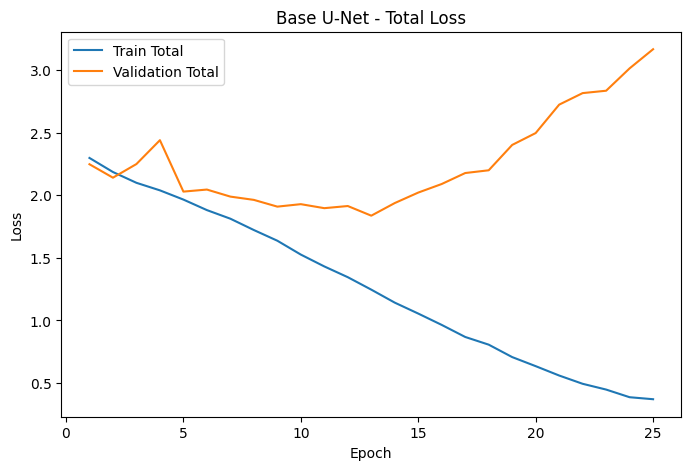

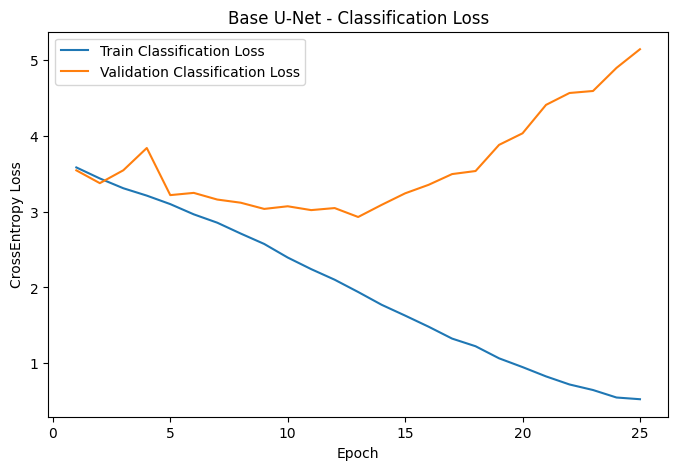

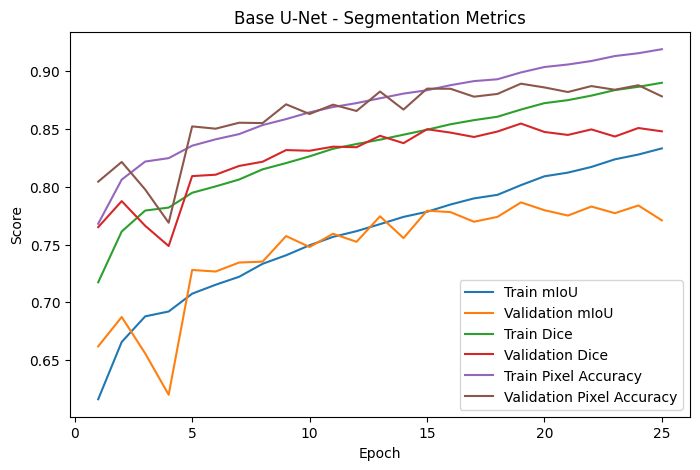

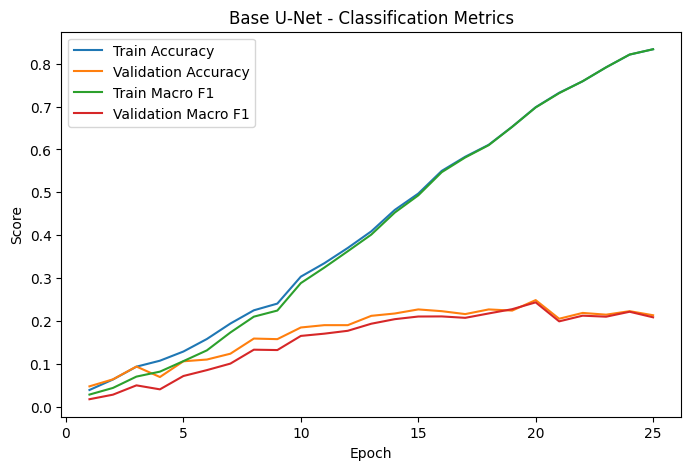

In [24]:
def plot_history(history, model_name):
    epochs = np.arange(1, len(history['train_total_loss']) + 1)

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history['train_total_loss'], label='Train Total')
    plt.plot(epochs, history['val_total_loss'], label='Validation Total')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title(model_name + ' - Total Loss')
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history['train_class_loss'], label='Train Classification Loss')
    plt.plot(epochs, history['val_class_loss'], label='Validation Classification Loss')
    plt.xlabel('Epoch')
    plt.ylabel('CrossEntropy Loss')
    plt.title(model_name + ' - Classification Loss')
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history['train_miou'], label='Train mIoU')
    plt.plot(epochs, history['val_miou'], label='Validation mIoU')
    plt.plot(epochs, history['train_dice'], label='Train Dice')
    plt.plot(epochs, history['val_dice'], label='Validation Dice')
    plt.plot(epochs, history['train_pixel_accuracy'], label='Train Pixel Accuracy')
    plt.plot(epochs, history['val_pixel_accuracy'], label='Validation Pixel Accuracy')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.title(model_name + ' - Segmentation Metrics')
    plt.legend()
    plt.show()

    plt.figure(figsize=(8, 5))
    plt.plot(epochs, history['train_class_accuracy'], label='Train Accuracy')
    plt.plot(epochs, history['val_class_accuracy'], label='Validation Accuracy')
    plt.plot(epochs, history['train_f1'], label='Train Macro F1')
    plt.plot(epochs, history['val_f1'], label='Validation Macro F1')
    plt.xlabel('Epoch')
    plt.ylabel('Score')
    plt.title(model_name + ' - Classification Metrics')
    plt.legend()
    plt.show()

plot_history(base_history, 'Base U-Net')


## 21. Required Base U-Net result summary for train, validation, and test

In [25]:
def make_result_table(encoder, bottleneck, decoder, classifier,
                      train_eval_loader, val_loader, test_loader,
                      bce_loss, dice_loss, classifier_loss_fn):
    train_stats = evaluate_model(
        encoder, bottleneck, decoder, classifier, train_eval_loader,
        bce_loss, dice_loss, classifier_loss_fn, NUM_CLASSES
    )
    val_stats = evaluate_model(
        encoder, bottleneck, decoder, classifier, val_loader,
        bce_loss, dice_loss, classifier_loss_fn, NUM_CLASSES
    )
    test_stats = evaluate_model(
        encoder, bottleneck, decoder, classifier, test_loader,
        bce_loss, dice_loss, classifier_loss_fn, NUM_CLASSES
    )

    table = pd.DataFrame([
        {'Set': 'Train', 'mIoU': train_stats['miou'], 'Dice': train_stats['dice'],
         'Pixel Accuracy': train_stats['pixel_accuracy'],
         'Classification Accuracy': train_stats['class_accuracy'],
         'Precision': train_stats['precision'], 'Recall': train_stats['recall'], 'F1': train_stats['f1']},
        {'Set': 'Validation', 'mIoU': val_stats['miou'], 'Dice': val_stats['dice'],
         'Pixel Accuracy': val_stats['pixel_accuracy'],
         'Classification Accuracy': val_stats['class_accuracy'],
         'Precision': val_stats['precision'], 'Recall': val_stats['recall'], 'F1': val_stats['f1']},
        {'Set': 'Test', 'mIoU': test_stats['miou'], 'Dice': test_stats['dice'],
         'Pixel Accuracy': test_stats['pixel_accuracy'],
         'Classification Accuracy': test_stats['class_accuracy'],
         'Precision': test_stats['precision'], 'Recall': test_stats['recall'], 'F1': test_stats['f1']}
    ])
    return table, train_stats, val_stats, test_stats


base_results, base_train_stats, base_val_stats, base_test_stats = make_result_table(
    base_encoder, base_bottleneck, base_decoder, base_classifier,
    train_eval_loader, val_loader, test_loader,
    base_bce_loss, base_dice_loss, base_classifier_loss_fn
)

print('BASE U-NET RESULT SUMMARY')
print(base_results.round(4))

BASE U-NET RESULT SUMMARY
          Set    mIoU    Dice  Pixel Accuracy  Classification Accuracy  \
0       Train  0.8355  0.8947          0.9202                   0.9154   
1  Validation  0.7709  0.8478          0.8781                   0.2133   
2        Test  0.7727  0.8498          0.8792                   0.2066   

   Precision  Recall      F1  
0     0.9212  0.9155  0.9164  
1     0.2235  0.2133  0.2085  
2     0.2216  0.2069  0.2061  


In [26]:
torch.save({
    'encoder': base_encoder.state_dict(),
    'bottleneck': base_bottleneck.state_dict(),
    'decoder': base_decoder.state_dict(),
    'classifier': base_classifier.state_dict(),
    'num_classes': NUM_CLASSES,
    'class_names': class_names,
    'class_species': class_species,
    'train_mean': train_mean,
    'train_std': train_std
}, 'base_unet_weights.pth')

print('Base U-Net weights saved.')

Base U-Net weights saved.


## 22. Required single-index prediction/demo function
This function is designed for the demonstration requirement. It accepts any index from the selected split and displays:

1. Original class and species.
2. Predicted class and species.
3. Foreground IoU.
4. Original image.
5. Image + true-mask overlay.
6. Image + predicted-mask overlay.

Original class  - "Leonberger" (Dog)
Predicted class - "Keeshond" (Dog)
IoU - 86.86%


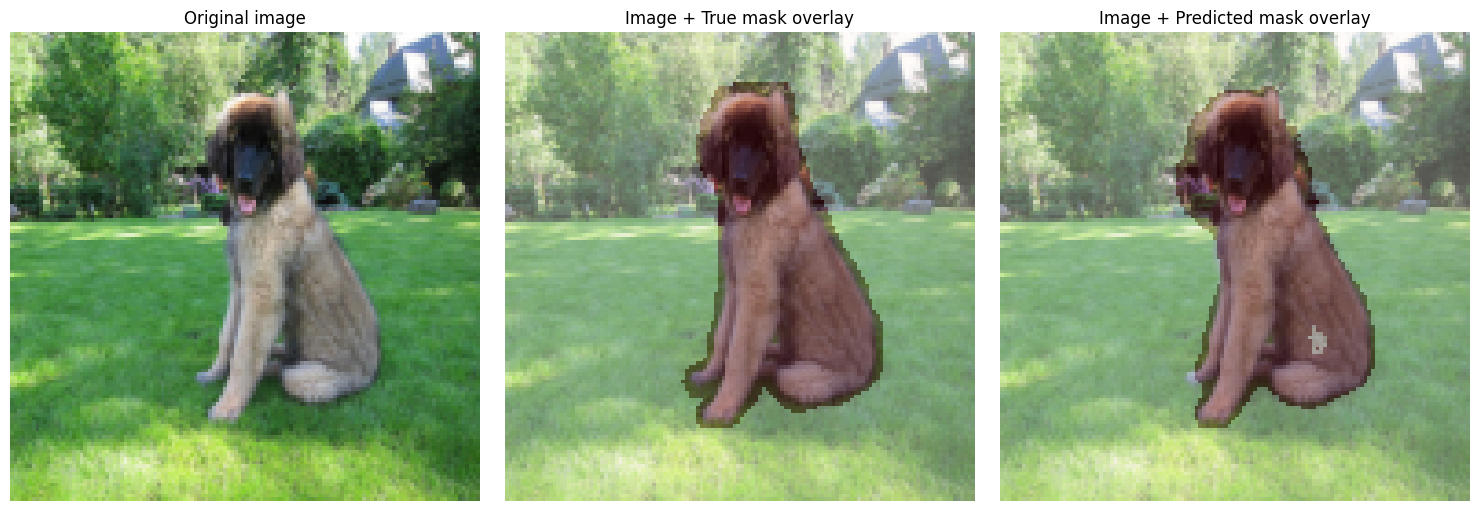

In [27]:
def predict_and_show(index, encoder, bottleneck, decoder, classifier, split='test', alpha=0.30):
    if split == 'train':
        x_data, y_masks, y_labels = x_train, y_mask_train, y_train
    elif split == 'validation':
        x_data, y_masks, y_labels = x_val, y_mask_val, y_val
    else:
        x_data, y_masks, y_labels = x_test, y_mask_test, y_test

    encoder.eval()
    bottleneck.eval()
    decoder.eval()
    classifier.eval()

    x_single = torch.tensor(x_data[index:index+1], device=device)
    true_mask = torch.tensor(y_masks[index:index+1], device=device)
    true_label = int(y_labels[index])

    with torch.no_grad():
        x1, x2, x3, x4 = encoder(x_single)
        x5 = bottleneck(x4)
        mask_logits = decoder(x5, x4, x3, x2, x1)
        class_logits = classifier(x4)

    pred_mask = (torch.sigmoid(mask_logits) > 0.5).float()
    pred_label = class_logits.argmax(dim=1).item()
    iou = calculate_iou(mask_logits, true_mask.float()).item()

    # Reverse the normalization for display
    display_image = x_data[index] * train_std[0] + train_mean[0]
    display_image = np.transpose(display_image, (1, 2, 0))
    display_image = np.clip(display_image, 0, 1)

    true_mask_np = y_masks[index]
    pred_mask_np = pred_mask.squeeze(0).cpu().numpy()

    print(f'Original class  - "{class_names[true_label]}" ({class_species[true_label]})')
    print(f'Predicted class - "{class_names[pred_label]}" ({class_species[pred_label]})')
    print(f'IoU - {iou * 100:.2f}%')

    plt.figure(figsize=(15, 5))

    plt.subplot(1, 3, 1)
    plt.imshow(display_image)
    plt.axis('off')
    plt.title('Original image')

    plt.subplot(1, 3, 2)
    plt.imshow(display_image)
    plt.imshow(true_mask_np, cmap='Reds', alpha=alpha)
    plt.axis('off')
    plt.title('Image + True mask overlay')

    plt.subplot(1, 3, 3)
    plt.imshow(display_image)
    plt.imshow(pred_mask_np, cmap='Reds', alpha=alpha)
    plt.axis('off')
    plt.title('Image + Predicted mask overlay')

    plt.tight_layout()
    plt.show()


# Presentation/demo example: use a random test index
random_test_index = np.random.randint(0, len(x_test))
predict_and_show(
    random_test_index,
    base_encoder, base_bottleneck, base_decoder, base_classifier,
    split='test'
)

# PART B — Attention U-Net + the Same Classifier

## 23. Attention gate
The uploaded labs do not contain a ready-made Attention U-Net implementation. To respect the source restriction, the gate below is built only from operations already used in Lab 8:

- `nn.Conv2d`
- `F.relu`
- `torch.sigmoid`
- multiplication
- skip-feature concatenation

The upsampled decoder feature acts as a **gating signal**. It is combined with the encoder skip feature to produce a 0–1 attention map. The encoder skip is multiplied by this map before concatenation.

In [28]:
class AttentionGate(nn.Module):
    def __init__(self, skip_channels, gate_channels, inter_channels):
        super().__init__()
        self.skip_conv = nn.Conv2d(skip_channels, inter_channels, kernel_size=1)
        self.gate_conv = nn.Conv2d(gate_channels, inter_channels, kernel_size=1)
        self.attention_conv = nn.Conv2d(inter_channels, 1, kernel_size=1)

    def forward(self, skip, gate):
        attention = F.relu(self.skip_conv(skip) + self.gate_conv(gate))
        attention = torch.sigmoid(self.attention_conv(attention))
        return skip * attention

## 24. Attention decoder block and Attention U-Net decoder
The only architectural change is in the skip path: instead of concatenating the raw encoder feature, the decoder concatenates the **attention-filtered** encoder feature.

In [29]:
class AttentionDecoderBlock(nn.Module):
    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_channels, out_channels, kernel_size=2, stride=2)
        self.attention = AttentionGate(
            skip_channels=out_channels,
            gate_channels=out_channels,
            inter_channels=max(out_channels // 2, 1)
        )
        self.conv = nn.Sequential(
            nn.Conv2d(2 * out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(),
            nn.Conv2d(out_channels, out_channels, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_channels),
            nn.ReLU()
        )

    def forward(self, x, skip):
        x = self.up(x)
        attended_skip = self.attention(skip, x)
        x = torch.cat([attended_skip, x], dim=1)
        x = self.conv(x)
        return x


class AttentionUNetDecoder(nn.Module):
    def __init__(self, in_channels=256):
        super().__init__()
        self.decode1 = AttentionDecoderBlock(in_channels, in_channels // 2)
        self.decode2 = AttentionDecoderBlock(in_channels // 2, in_channels // 4)
        self.decode3 = AttentionDecoderBlock(in_channels // 4, in_channels // 8)
        self.decode4 = AttentionDecoderBlock(in_channels // 8, in_channels // 16)
        self.final_conv = nn.Conv2d(in_channels // 16, 1, kernel_size=1)

    def forward(self, x5, x4, x3, x2, x1):
        x = self.decode1(x5, x4)
        x = self.decode2(x, x3)
        x = self.decode3(x, x2)
        x = self.decode4(x, x1)
        x = self.final_conv(x).squeeze(1)
        return x

## 25. Train Attention U-Net with the same corrected classifier
The Attention U-Net uses the same encoder-output classifier head (`x4 -> Classifier`) and the same stable training settings. This makes Base U-Net vs Attention U-Net comparison fair.

In [30]:
# Fresh loaders so their iteration state is clean
train_loader_attention = BatchLoader(x_train, y_mask_train, y_train, shuffle=True, batch_size=BATCH_SIZE, device=device)
val_loader_attention = BatchLoader(x_val, y_mask_val, y_val, shuffle=False, batch_size=BATCH_SIZE, device=device)
test_loader_attention = BatchLoader(x_test, y_mask_test, y_test, shuffle=False, batch_size=BATCH_SIZE, device=device)
train_eval_loader_attention = BatchLoader(x_train, y_mask_train, y_train, shuffle=False, batch_size=BATCH_SIZE, device=device)

attention_encoder = UNetEncoder(in_channels=3, first_out_channel=16).to(device)
attention_bottleneck = UNetBottleneck(in_channels=128).to(device)
attention_decoder = AttentionUNetDecoder(in_channels=256).to(device)
attention_classifier = Classifier(in_channels=128, num_classes=NUM_CLASSES).to(device)

attention_history, attention_bce_loss, attention_dice_loss, attention_classifier_loss_fn = train_model(
    attention_encoder, attention_bottleneck, attention_decoder, attention_classifier,
    train_loader_attention, val_loader_attention,
    epochs=EPOCHS,
    lr=LEARNING_RATE,
    num_classes=NUM_CLASSES
)

Epoch 1 / 25
Train | Total 2.2841 | SegLoss 0.3611 | ClassLoss 3.5661 | mIoU 0.6125 | Dice 0.7229 | Pixel Acc 0.7640 | Class Acc 0.0404 | F1 0.0286
Val   | Total 2.4060 | SegLoss 0.3491 | ClassLoss 3.7772 | mIoU 0.6255 | Dice 0.7413 | Pixel Acc 0.7729 | Class Acc 0.0543 | F1 0.0183

Epoch 2 / 25
Train | Total 2.1977 | SegLoss 0.3040 | ClassLoss 3.4601 | mIoU 0.6692 | Dice 0.7642 | Pixel Acc 0.8089 | Class Acc 0.0547 | F1 0.0369
Val   | Total 2.2183 | SegLoss 0.2844 | ClassLoss 3.5075 | mIoU 0.6832 | Dice 0.7799 | Pixel Acc 0.8199 | Class Acc 0.0489 | F1 0.0213

Epoch 3 / 25
Train | Total 2.1215 | SegLoss 0.2918 | ClassLoss 3.3413 | mIoU 0.6804 | Dice 0.7732 | Pixel Acc 0.8173 | Class Acc 0.0842 | F1 0.0647
Val   | Total 2.0921 | SegLoss 0.2685 | ClassLoss 3.3079 | mIoU 0.7068 | Dice 0.7953 | Pixel Acc 0.8363 | Class Acc 0.0774 | F1 0.0520

Epoch 4 / 25
Train | Total 2.0163 | SegLoss 0.2716 | ClassLoss 3.1794 | mIoU 0.7026 | Dice 0.7910 | Pixel Acc 0.8321 | Class Acc 0.1101 | F1 0.0915


## 26. Required Attention U-Net training curves

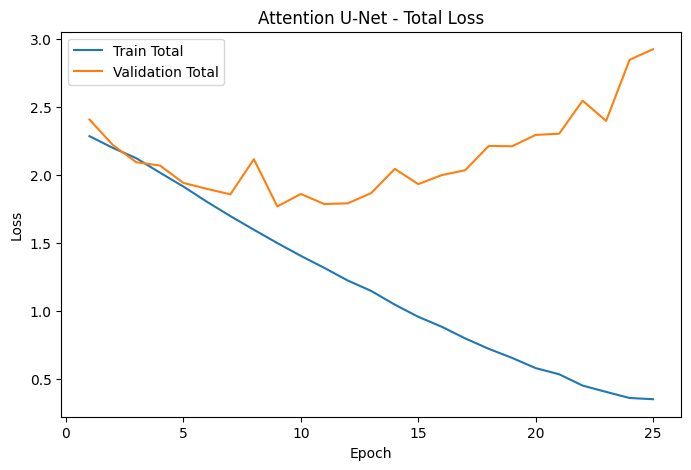

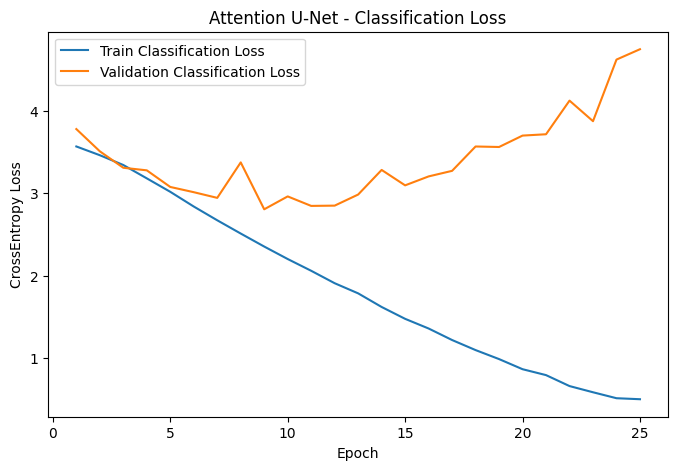

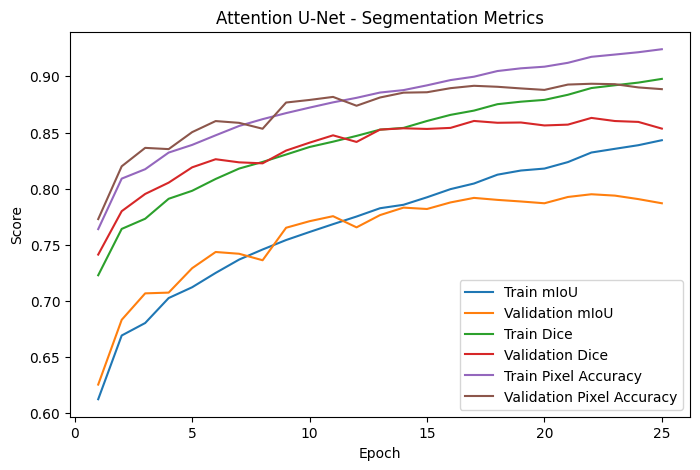

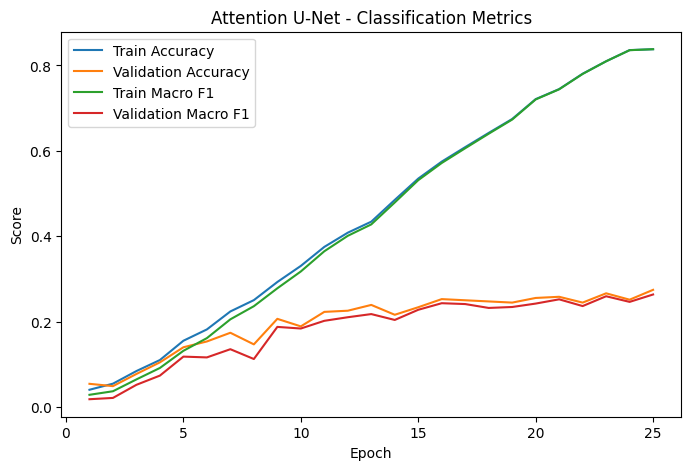

In [31]:
plot_history(attention_history, 'Attention U-Net')

## 27. Required Attention U-Net result summary for train, validation, and test

In [32]:
attention_results, attention_train_stats, attention_val_stats, attention_test_stats = make_result_table(
    attention_encoder, attention_bottleneck, attention_decoder, attention_classifier,
    train_eval_loader_attention, val_loader_attention, test_loader_attention,
    attention_bce_loss, attention_dice_loss, attention_classifier_loss_fn
)

print('ATTENTION U-NET RESULT SUMMARY')
print(attention_results.round(4))


ATTENTION U-NET RESULT SUMMARY
          Set    mIoU    Dice  Pixel Accuracy  Classification Accuracy  \
0       Train  0.8574  0.9073          0.9330                   0.8967   
1  Validation  0.7870  0.8535          0.8886                   0.2745   
2        Test  0.7879  0.8556          0.8897                   0.2488   

   Precision  Recall      F1  
0     0.9066  0.8970  0.8978  
1     0.2798  0.2752  0.2636  
2     0.2619  0.2503  0.2440  


In [33]:
torch.save({
    'encoder': attention_encoder.state_dict(),
    'bottleneck': attention_bottleneck.state_dict(),
    'decoder': attention_decoder.state_dict(),
    'classifier': attention_classifier.state_dict(),
    'num_classes': NUM_CLASSES,
    'class_names': class_names,
    'class_species': class_species,
    'train_mean': train_mean,
    'train_std': train_std
}, 'attention_unet_weights.pth')

print('Attention U-Net weights saved.')

Attention U-Net weights saved.


## 28. Required Attention U-Net prediction/demo visualization

Original class  - "Pug" (Dog)
Predicted class - "Pug" (Dog)
IoU - 95.01%


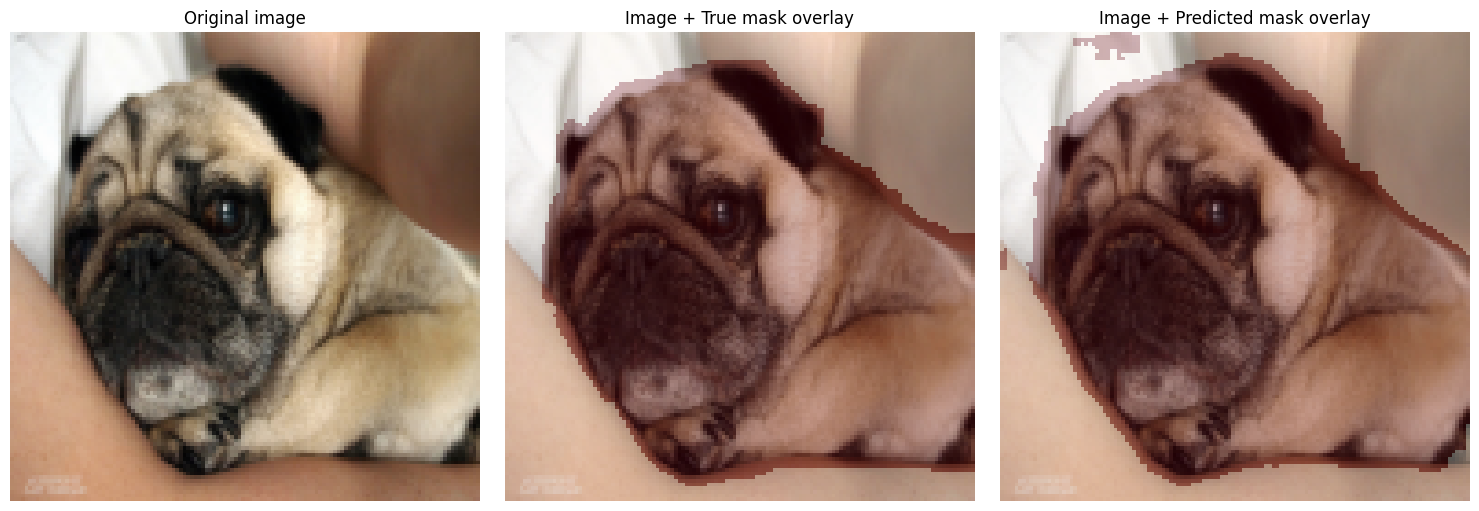

In [34]:
random_test_index = np.random.randint(0, len(x_test))
predict_and_show(
    random_test_index,
    attention_encoder, attention_bottleneck, attention_decoder, attention_classifier,
    split='test'
)

# PART C — Final Comparison

## 29. Base U-Net vs Attention U-Net on the test set
This table is the clearest final result to show during presentation/viva.

In [35]:
comparison = pd.DataFrame([
    {
        'Model': 'Base U-Net',
        'mIoU': base_test_stats['miou'],
        'Dice': base_test_stats['dice'],
        'Pixel Accuracy': base_test_stats['pixel_accuracy'],
        'Classification Accuracy': base_test_stats['class_accuracy'],
        'Precision': base_test_stats['precision'],
        'Recall': base_test_stats['recall'],
        'F1': base_test_stats['f1']
    },
    {
        'Model': 'Attention U-Net',
        'mIoU': attention_test_stats['miou'],
        'Dice': attention_test_stats['dice'],
        'Pixel Accuracy': attention_test_stats['pixel_accuracy'],
        'Classification Accuracy': attention_test_stats['class_accuracy'],
        'Precision': attention_test_stats['precision'],
        'Recall': attention_test_stats['recall'],
        'F1': attention_test_stats['f1']
    }
])

print('FINAL TEST-SET COMPARISON')
print(comparison.round(4))


FINAL TEST-SET COMPARISON
             Model    mIoU    Dice  Pixel Accuracy  Classification Accuracy  \
0       Base U-Net  0.7727  0.8498          0.8792                   0.2066   
1  Attention U-Net  0.7879  0.8556          0.8897                   0.2488   

   Precision  Recall      F1  
0     0.2216  0.2069  0.2061  
1     0.2619  0.2503  0.2440  


## 30. Final presentation/demo helper
Set `MODEL_TO_DEMO` to either `'base'` or `'attention'`, choose any test index, and run the cell. This avoids searching through the notebook during the demonstration.

Original class  - "American Pit Bull Terrier" (Dog)
Predicted class - "Japanese Chin" (Dog)
IoU - 69.50%


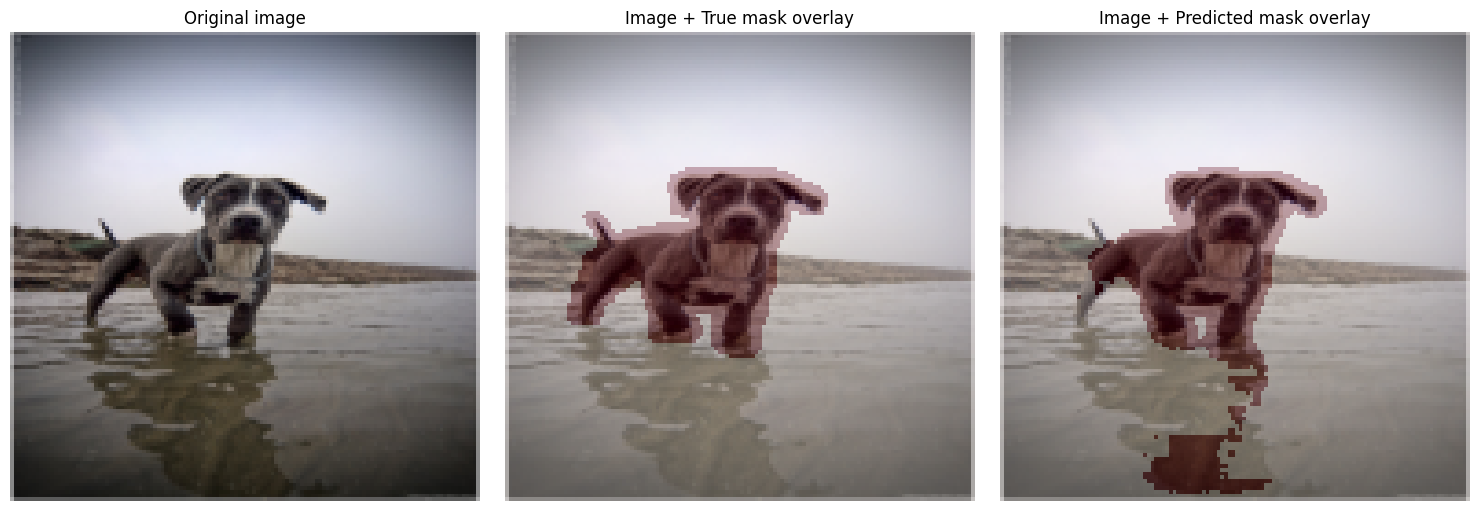

In [36]:
MODEL_TO_DEMO = 'attention'   # change to 'base' if needed
DEMO_INDEX = np.random.randint(0, len(x_test))

if MODEL_TO_DEMO == 'base':
    predict_and_show(
        DEMO_INDEX,
        base_encoder, base_bottleneck, base_decoder, base_classifier,
        split='test'
    )
else:
    predict_and_show(
        DEMO_INDEX,
        attention_encoder, attention_bottleneck, attention_decoder, attention_classifier,
        split='test'
    )

In [37]:
from google.colab import files

files.download('base_unet_weights.pth')
files.download('attention_unet_weights.pth')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>